# Hệ thống Phân tích Cảm xúc TikTok Song ngữ (Tiếng Việt & Tiếng Anh)

- **Dữ liệu thu thập (`data/<post_id>/`):** Tự động tải video (`video.mp4`), `metadata.json` và bình luận thô (`raw_comments.csv`).
- **Giai đoạn 1 — AI Đầu vào (`gemma4-e2b-opt`):** Đọc khung hình + lời thoại Whisper (tự nhận diện VI/EN) + caption để trích xuất 8 trường ngữ cảnh bài đăng.
- **Giai đoạn 2 — Tiền xử lý & Lọc nhiễu (`src/preprocessing/text_cleaner.py`):** Nhận diện ngôn ngữ (`vi` / `en`), lọc bình luận nhiễu (`@tag` bạn bè, tên riêng đơn lẻ qua `underthesea`, URL, seeding, spam quảng cáo, ngôn ngữ khác `FILTERED_UNSUPPORTED_LANG`).
- **Giai đoạn 3 — Lõi ML & Deep Learning (`src/models/classical_ml.py` + `sentiment_engine.py`):**
  - **Tiếng Việt:** `TF-IDF (NB/LR/SVM)` + `Vietnamese Lexicon` + `ViSoBERT` + `PhoBERT` + `PhoBERT Emotion (7 cung bậc)`.
  - **Tiếng Anh:** `TF-IDF (NB/LR/SVM)` + `English Lexicon` + `Twitter-RoBERTa` + `DistilRoBERTa Emotion (7 cung bậc)`.
  - **Thang điểm kép nhất quán:** `polarity_score` (`-1.0..+1.0`), `score_5` (`1..5`), `score_10` (`0..10`).
- **Giai đoạn 4 — AI Đầu ra (`src/models/gemma_auditor.py`):** `gemma4-e2b-opt` thẩm định thực tế **100% bình luận hợp lệ**, phát hiện nói mỉa (`sarcasm`) và xuất kết quả cuối cùng ra **`outputs/<post_id>/`**.

> Đảm bảo container Ollama `gemma4-e2b` đang chạy (`docker compose up -d` trong `AI_Local/gemma4-e2b`) trước khi chạy.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src.pipeline import SentimentPipeline
from src.visualization import plot_sentiment_dashboard

# === NHẬP LINK VIDEO / ẢNH TIKTOK ===
TIKTOK_URL = input("Nhập link video/ảnh TikTok: ").strip()

# Cấu hình hệ thống
ENABLE_AUDIO = True
RUN_AI_AUDIT = True          # Gemma 4 E2B thẩm định thực tế ở đầu ra
AUDIT_LIMIT = None           # None = chấm 100% bình luận hợp lệ
MAX_COMMENTS = 200
DEDUPLICATE_STATS = False    # True nếu muốn loại bỏ bình luận copy-paste khỏi tỷ lệ %
DATA_DIR = Path("data")      # Nơi lưu toàn bộ dữ liệu thu thập thô
OUTPUT_DIR = Path("outputs") # Nơi xuất kết quả cuối cùng sau xử lý

In [ ]:
# === CHẠY TOÀN BỘ PIPELINE 4 GIAI ĐOẠN ===
if not TIKTOK_URL:
    raise ValueError("Vui lòng nhập link video TikTok vào biến TIKTOK_URL.")

pipeline = SentimentPipeline()
report = pipeline.run(
    tiktok_url=TIKTOK_URL,
    enable_audio=ENABLE_AUDIO,
    run_ai_audit=RUN_AI_AUDIT,
    audit_limit=AUDIT_LIMIT,
    max_comments=MAX_COMMENTS,
    deduplicate_stats=DEDUPLICATE_STATS,
    data_dir=DATA_DIR,
    output_dir=OUTPUT_DIR,
)

run_name = report["run_name"]
print(f"-> Dữ liệu thu thập lưu tại: {DATA_DIR / run_name}")
print(f"-> Kết quả xử lý xuất tại  : {OUTPUT_DIR / run_name}")

if report.get("media_analysis"):
    print("\n=== GIAI ĐOẠN 1: NGỮ CẢNH VIDEO / ẢNH (GEMMA 4 E2B) ===")
    print(json.dumps(report["media_analysis"], ensure_ascii=False, indent=2))

[Bước 0] Đang tải video/ảnh & metadata vào data\7666481155348237576...
Đang mở trình duyệt tới bài viết Photo Mode: https://www.tiktok.com/@meo4599/photo/7666481155348237576?q=%E1%BA%A3nh&t=1795493086335

[Tạm dừng] Trên cửa sổ Microsoft Edge vừa mở:
  1. Đóng popup đăng nhập (hoặc đăng nhập nếu TikTok yêu cầu).
  2. Đảm bảo ảnh bài viết (và phần bình luận nếu cần) đã hiển thị / hoàn tất xác minh.
  Lần cuộn 1/40: thu được 39 bình luận
  Lần cuộn 2/40: thu được 63 bình luận
  Lần cuộn 3/40: thu được 86 bình luận
  Lần cuộn 4/40: thu được 112 bình luận
  Lần cuộn 5/40: thu được 129 bình luận
  Lần cuộn 6/40: thu được 152 bình luận
  Lần cuộn 7/40: thu được 178 bình luận
  Lần cuộn 8/40: thu được 192 bình luận
  Lần cuộn 9/40: thu được 210 bình luận
Đã đạt giới hạn 200 bình luận.
[Giai đoạn 1] Gemma 4 E2B đang phân tích ngữ cảnh video/ảnh...
[Giai đoạn 2] Lọc nhiễu, nhận diện ngôn ngữ (VI/EN) & tách từ (200 bình luận)...
  -> Hợp lệ: 188 | Đã lọc nhiễu: 12
[Giai đoạn 3] Đang chạy ML cổ đ

Model phobert-emotion: 100%|██████████| 6/6 [00:03<00:00,  1.63batch/s]
Some weights of the model checkpoint at cardiffnlp/twitter-roberta-base-sentiment-latest were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Model emotion-english-distilroberta-base: 100%|██████████| 1/1 [00:00<00:00,  1.40batch/s]


[Giai đoạn 4] Gemma 4 E2B đang thẩm định thực tế bình luận theo ngữ cảnh...


Gemma 4 E2B thẩm định thực tế:   0%|          | 0/24 [00:00<?, ?batch/s]

In [ ]:
# === XEM KẾT QUẢ TÁCH BIỆT COMMENT SẠCH & COMMENT NHIỄU ===
print("=== THỐNG KÊ LỌC NHIỄU & NGÔN NGỮ ===")
print(json.dumps(report["noise_filter_summary"], ensure_ascii=False, indent=2))
if report.get("sentiment_summary"):
    print("Phân bố ngôn ngữ hợp lệ:", report["sentiment_summary"]["language_counts"])

exported = report.get("exported_files", {})
if "cleaned_final_results_csv" in exported:
    df_summary = pd.read_csv(exported["cleaned_final_results_csv"], encoding="utf-8-sig")
    print(f"\nBảng tóm gọn các cột chính (cleaned_final_results.csv): {len(df_summary)} dòng")
    display(df_summary.head(20))

if "final_results_csv" in exported:
    df_clean = pd.read_csv(exported["final_results_csv"], encoding="utf-8-sig")
    df_clean.columns = [c.split("\n", 1)[0] for c in df_clean.columns]
    print(f"\nSố comment sạch đầy đủ 42 cột (final_results.csv): {len(df_clean)}")
    display(df_clean[[
        "language", "original_text", "polarity_label", "polarity_score", "score_5", "score_10",
        "emotion_vi", "pred_nb", "pred_lr", "pred_svm", "pred_dl_primary",
        "gemma_polarity", "gemma_emotion_vi", "gemma_score_5", "gemma_is_sarcasm", "gemma_reason"
    ]].head(20))

if "filtered_noise_csv" in exported:
    df_noise = pd.read_csv(exported["filtered_noise_csv"], encoding="utf-8-sig")
    print(f"\nSố comment bị lọc nhiễu (filtered_noise.csv): {len(df_noise)}")
    display(df_noise.head(20))

=== THỐNG KÊ LỌC NHIỄU & NGÔN NGỮ ===
{
  "total_raw_comments": 179,
  "valid_comments": 135,
  "filtered_noise_count": 44,
  "duplicate_valid_count": 0,
  "filter_reasons": {
    "FILTERED_URL_OR_SYMBOL": 36,
    "FILTERED_MEANINGLESS": 3,
    "FILTERED_TAG_FRIEND": 5
  }
}
Phân bố ngôn ngữ hợp lệ: {'vi': 130, 'en': 5}

Bảng tóm gọn các cột chính (cleaned_final_results.csv): 135 dòng


,username\n(tên tài khoản),likes\n(lượt thích),created_at\n(thời gian đăng),language\n(ngôn ngữ),original_text\n(nội dung gốc),polarity_vi\n(cực tính hệ thống),score_5\n(điểm thang 1-5),score_10\n(điểm thang 0-10),emotion_vi\n(cảm xúc 7 cung bậc),polarity_confidence\n(độ tự tin cực tính),gemma_polarity_vi\n(cực tính gemma tiếng việt),gemma_score_5\n(điểm 1-5 gemma),gemma_is_sarcasm\n(nói mỉa theo gemma),gemma_agrees_polarity\n(khớp cực tính với gemma),gemma_reason\n(lý do gemma giải thích)
0,diinh.ba.phong,5800,2026-11-01 12:57:48,vi,luôn luôn là threads,Tích cực,5,8.06,Vui vẻ / Hài lòng,0.6241,Trung tính,3,False,False,Bình luận này chỉ đơn thuần là nhận xét về địn...
1,xaahdyk,4720,2026-11-01 12:57:14,vi,Giờ cái threads nát lắm r,Tiêu cực,1,1.56,Buồn bã,0.7623,Trung tính,3,False,False,Bình luận này mang tính chất than thở chung ch...
2,phong.truong694,1708,2026-11-01 12:36:25,vi,gom link đê,Trung tính,3,4.92,Chán ghét / Khó chịu,0.3946,Trung tính,3,False,True,Đây là một yêu cầu hành động cụ thể (gom link)...
3,hoangminhtriet812,654,2026-11-01 13:08:49,vi,ko có địa chỉ ra cúng kiểu j,Tiêu cực,1,0.75,Chán ghét / Khó chịu,0.7977,Trung tính,3,False,False,Bình luận này là một câu hỏi hoặc nhận xét man...
4,1283405tthuc,553,2026-11-01 12:51:30,vi,Clip này nên xh. Ông anh này đã dành thời gian...,Trung tính,3,5.84,Vui vẻ / Hài lòng,0.5303,Tích cực,5,False,False,Người dùng bày tỏ sự đánh giá cao về nội dung ...
5,tamchieu02,172,2026-11-01 13:53:34,vi,1 phút mặt kệ bắt đầu,Trung tính,3,5.45,Trung tính / Khác,0.5998,Trung tính,3,False,True,Bình luận này là một nhận xét ngắn gọn về thời...
6,d.a1541800,65,2026-11-01 13:17:42,vi,A ơi chúng nó vẫn nói là Trung Quốc nó đánh th...,Tiêu cực,1,1.13,Chán ghét / Khó chịu,0.7781,Tiêu cực,2,False,True,Người dùng bày tỏ sự không đồng tình mạnh mẽ v...
7,benimaru1104,59,2026-11-01 12:52:01,vi,bọn threads điên lắm r,Tiêu cực,2,3.95,Tức giận,0.4423,Trung tính,3,False,False,Bình luận này là một nhận xét chung chung về c...
8,thnh.phc9349,44,2026-11-01 14:07:28,vi,mai là 1 ngày tồi tệ,Tiêu cực,1,0.82,Buồn bã,0.8320,Tiêu cực,2,False,True,Bình luận thể hiện sự tiêu cực và dự đoán về m...
9,flicknhanhnhatvn201,42,2026-11-01 11:34:04,vi,Đây rồi =)),Tích cực,5,8.32,Vui vẻ / Hài lòng,0.6512,Trung tính,3,False,False,"Đây là một phản ứng ngắn gọn, mang tính xác nh..."



Số comment sạch đầy đủ 42 cột (final_results.csv): 135


,language,original_text,polarity_label,polarity_score,score_5,score_10,emotion_vi,pred_nb,pred_lr,pred_svm,pred_dl_primary,gemma_polarity,gemma_emotion_vi,gemma_score_5,gemma_is_sarcasm,gemma_reason
0,vi,Giờ cái threads nát lắm r,NEG,-0.6887,1,1.56,Buồn bã,NEG,NEG,NEG,NEG,NEU,Trung tính / Khác,3,False,Bình luận này mang tính chất than thở chung ch...
1,vi,gom link đê,NEU,-0.0163,3,4.92,Chán ghét / Khó chịu,NEU,NEG,NEG,NEU,NEU,Trung tính / Khác,3,False,Đây là một yêu cầu hành động cụ thể (gom link)...
2,vi,luôn luôn là threads,POS,0.6114,5,8.06,Vui vẻ / Hài lòng,POS,POS,POS,POS,NEU,Trung tính / Khác,3,False,Bình luận này chỉ đơn thuần là nhận xét về địn...
3,vi,ko có địa chỉ ra cúng kiểu j,NEG,-0.8496,1,0.75,Chán ghét / Khó chịu,NEG,NEG,NEG,NEG,NEU,Trung tính / Khác,3,False,Bình luận này là một câu hỏi hoặc nhận xét man...
4,vi,1 phút mặt kệ bắt đầu,NEU,0.0892,3,5.45,Trung tính / Khác,NEG,NEU,NEU,NEU,NEU,Trung tính / Khác,3,False,Bình luận này là một nhận xét ngắn gọn về thời...
5,vi,Clip này nên xh. Ông anh này đã dành thời gian...,NEU,0.1673,3,5.84,Vui vẻ / Hài lòng,NEG,NEU,NEU,NEU,POS,Vui vẻ / Hài lòng,5,False,Người dùng bày tỏ sự đánh giá cao về nội dung ...
6,vi,nổ cái địa chỉ mình ra đào kho báu phát 😂😂😂,POS,0.5048,4,7.52,Vui vẻ / Hài lòng,NEG,NEU,NEG,POS,POS,Vui vẻ / Hài lòng,4,False,Bình luận thể hiện sự hào hứng và thích thú vớ...
7,vi,ủa lỡ ngta nói kháy thì s:),NEG,-0.2726,2,3.64,Trung tính / Khác,NEG,NEU,NEU,NEG,NEU,Trung tính / Khác,3,False,Đây là một câu hỏi mang tính thăm dò về phản ứ...
8,vi,ngon có cơ hội hâm mộ,POS,0.8809,5,9.40,Vui vẻ / Hài lòng,POS,POS,POS,POS,POS,Vui vẻ / Hài lòng,5,False,Bình luận thể hiện sự ngưỡng mộ và mong muốn ủ...
9,vi,hay quá tặng anh,POS,0.9396,5,9.70,Vui vẻ / Hài lòng,POS,POS,POS,POS,POS,Vui vẻ / Hài lòng,5,False,Bình luận thể hiện sự thích thú và mong muốn t...



Số comment bị lọc nhiễu (filtered_noise.csv): 44


,comment_id,username,nickname,likes,language,original_text,cleaned_text,filter_reason
0,7703092439926326017,_you.broke.my.heart3667_,tôi đã lớn rồi🥵😭🙏💔🥀,3,vi,https://vt.tiktok.com/ZSgw1XHJh/,NaN,FILTERED_URL_OR_SYMBOL
1,7711323979143021330,baonguyen140520,Bảo bảo,0,vi,https://vt.tiktok.com/ZSsL1Encw/,NaN,FILTERED_URL_OR_SYMBOL
2,7703225770948985618,cuonq_nho_em,cuonq pw,1,vi,https://vt.tiktok.com/ZSgKY9Kje/,NaN,FILTERED_URL_OR_SYMBOL
3,7703071747369960213,nguoikinhchoitiktok,gphuc,2,vi,https://vt.tiktok.com/ZSgTWXfXG/,NaN,FILTERED_URL_OR_SYMBOL
4,7703184156197421845,10th714,Kẻ thống trị loài bò🐮,0,vi,https://vt.tiktok.com/ZSgwn3jke/,NaN,FILTERED_URL_OR_SYMBOL
5,7707829650496799506,haiyw.0,hai yen,0,vi,https://vt.tiktok.com/ZSpX2C8Lr/,NaN,FILTERED_URL_OR_SYMBOL
6,7703211561909355285,nguyencao456,𝓜𝓪𝓽𝓬𝓱𝓪 𝓮𝓭𝓲𝓽𝔃🍵🍵,1,vi,https://vt.tiktok.com/ZSgKda7QS/,NaN,FILTERED_URL_OR_SYMBOL
7,7708709470272701185,dbbq2014,"Đời bố,bố quản",0,vi,https://vt.tiktok.com/ZSppHSoQT/,NaN,FILTERED_URL_OR_SYMBOL
8,7705670507589518087,mk02112014ars,M_K💝,0,vi,xu hướng,xu hướng,FILTERED_MEANINGLESS
9,7703099548806464276,toilaminh69,egonist a5 tẩm quất,1,vi,https://vt.tiktok.com/ZSgwdpPAt/,NaN,FILTERED_URL_OR_SYMBOL


In [ ]:
# === SO SÁNH CÁC MÔ HÌNH ML CỔ ĐIỂN VS DEEP LEARNING VS HYBRID ===
comp = report.get("model_comparison", {})
if comp.get("polarity_models"):
    print("=== BẢNG SO SÁNH MÔ HÌNH POLARITY ===")
    display(pd.DataFrame(comp["polarity_models"]))

if comp.get("emotion_models"):
    print("\n=== BẢNG SO SÁNH MÔ HÌNH 7 CẢM XÚC ===")
    display(pd.DataFrame(comp["emotion_models"]))

if report.get("ai_audit_verdict"):
    print("\n=== KẾT LUẬN THẨM ĐỊNH ĐẦU RA (GEMMA 4 E2B) ===")
    print(json.dumps(report["ai_audit_verdict"], ensure_ascii=False, indent=2))

if report.get("keywords_tfidf"):
    print("\n=== TỪ KHÓA NỔI BẬT (TF-IDF) ===")
    print(json.dumps(report["keywords_tfidf"], ensure_ascii=False, indent=2))

=== BẢNG SO SÁNH MÔ HÌNH POLARITY ===


,model,family,total_comments,pos_count,neu_count,neg_count,pos_pct,neu_pct,neg_pct,agreement_vs_gemma_pct,macro_f1_vs_gemma,cohen_kappa_vs_gemma,score_5_mae_vs_gemma,inference_time_sec
0,TF-IDF + Naive Bayes,Classical ML,135,21,38,76,15.56,28.15,56.30,41.48,0.4079,0.1547,NaN,0.055
1,TF-IDF + Logistic Regression,Classical ML,135,33,49,53,24.44,36.30,39.26,53.33,0.5266,0.2904,NaN,0.055
2,TF-IDF + Linear SVM,Classical ML,135,38,29,68,28.15,21.48,50.37,43.70,0.4461,0.2123,NaN,0.055
3,Bilingual Lexicon + Rules,Rule-based NLP,135,14,114,7,10.37,84.44,5.19,63.70,0.4592,0.2323,NaN,0.002
4,"ViSoBERT (5CD-AI, VI)",Deep Learning,130,73,15,42,56.15,11.54,32.31,35.38,0.3427,0.1347,NaN,9.830
5,PhoBERT (VI) / Twitter-RoBERTa (EN),Deep Learning,135,32,56,47,23.70,41.48,34.81,54.07,0.5239,0.2796,NaN,12.331
6,Hybrid Ensemble (Hệ thống chính),Hybrid ML + DL,135,34,55,46,25.19,40.74,34.07,54.81,0.5272,0.2940,0.837,NaN
7,Gemma 4 E2B (Thẩm định ngữ cảnh),Multimodal LLM Reference,135,30,79,26,22.22,58.52,19.26,100.00,1.0000,1.0000,0.000,191.805



=== BẢNG SO SÁNH MÔ HÌNH 7 CẢM XÚC ===


,model,family,agreement_vs_gemma_pct,macro_f1_vs_gemma,inference_time_sec
0,TF-IDF + Logistic Regression (Emotion),Classical ML,46.67,0.2447,0.014
1,PhoBERT Emotion (VI) / DistilRoBERTa (EN),Deep Learning,48.89,0.2688,10.981



=== KẾT LUẬN THẨM ĐỊNH ĐẦU RA (GEMMA 4 E2B) ===
{
  "accuracy_verdict": "Trung bình (cần cải thiện)",
  "best_model": "Gemma 4 E2B (Thẩm định ngữ cảnh)",
  "strengths": [
    "Model Gemma 4 E2B đạt độ chính xác tuyệt đối (100.0%) trong việc thẩm định ngữ cảnh, cho thấy khả năng hiểu sâu sắc về sắc thái và ngữ cảnh của nội dung thảo luận (đặc biệt là các quan điểm chính trị/lịch sử).",
    "Các mô hình Ensemble (Hybrid Ensemble) cho thấy hiệu suất tổng thể tốt (agreement_pct: 54.81), phản ánh khả năng tổng hợp thông tin đa chiều."
  ],
  "weaknesses": [
    "Các mô hình dựa trên thống kê truyền thống (TF-IDF + Naive Bayes, Logistic Regression) có độ chính xác thấp hơn đáng kể (macro_f1 thấp), cho thấy chúng gặp khó khăn trong việc nắm bắt các sắc thái phức tạp và ngữ cảnh đa ngôn ngữ.",
    "Sự khác biệt giữa dự đoán của mô hình Hybrid và Gemma 4 cho thấy các mô hình khác đang đánh giá sai sắc thái cảm xúc (ví dụ: dự đoán NEG/POS khác biệt so với sự thật của Gemma 4).",
    "Mô hình Bi

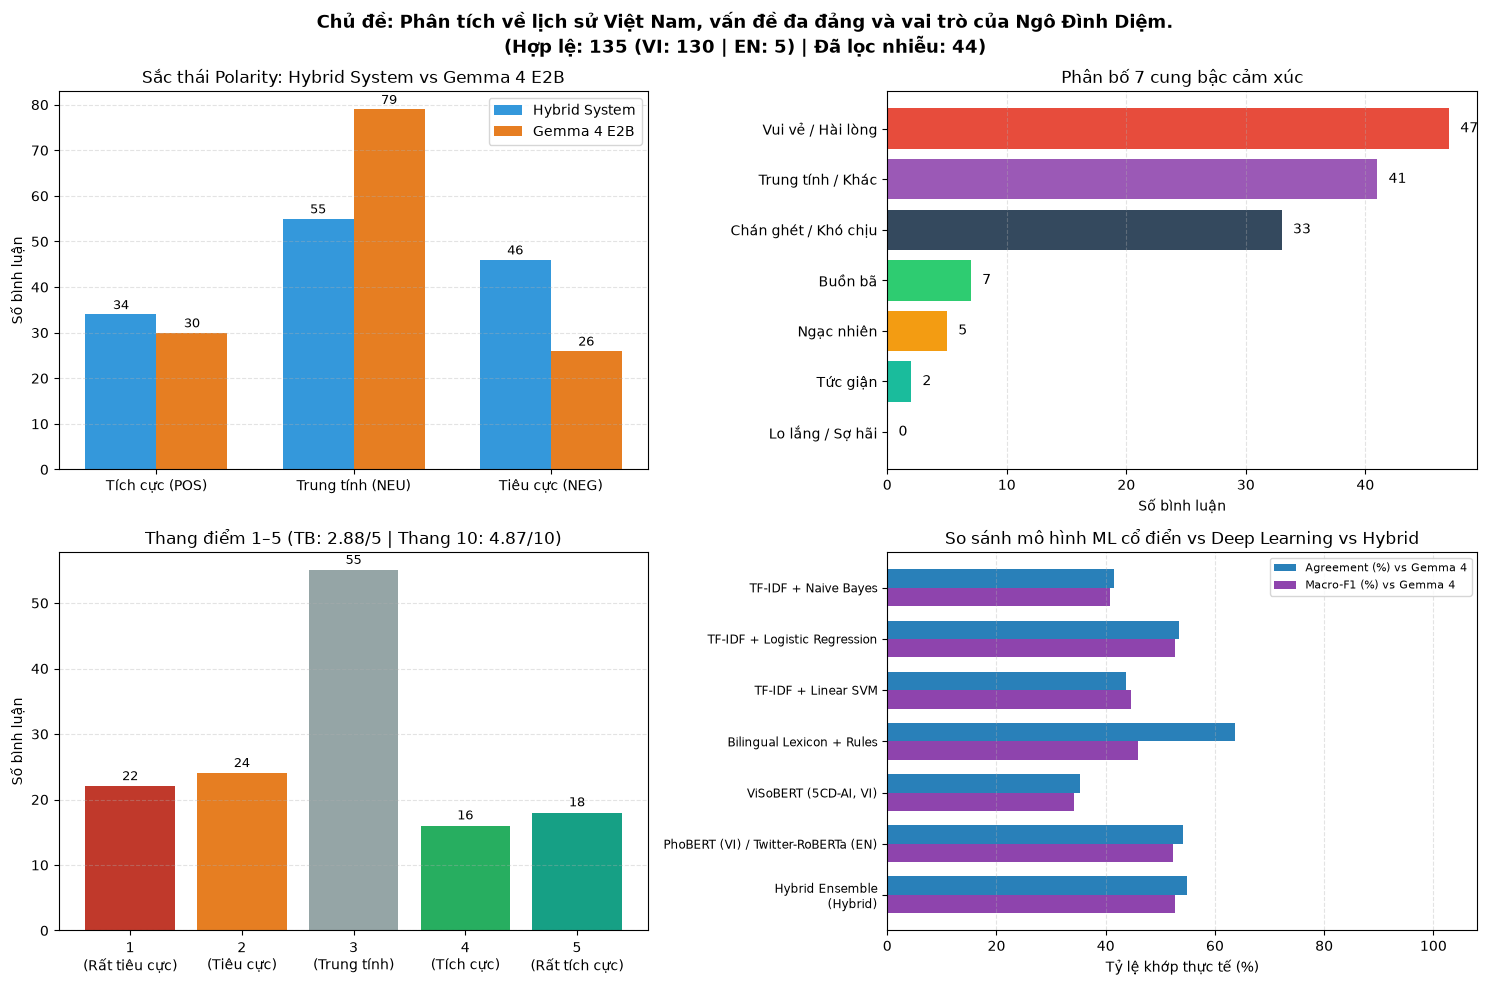

In [ ]:
# === DASHBOARD TRỰC QUAN HÓA ===
exported = report.get("exported_files", {})
chart_path = exported.get("dashboard_png") or (OUTPUT_DIR / report["run_name"] / "dashboard.png")
fig = plot_sentiment_dashboard(report, save_path=chart_path)
plt.show()